# Lab 28-08 · Synergies, Paths and Registers

Companion to [chapter 28-08](../../chapters/28-08-integration-risk.md). Every part asks you to **predict first**, then run. Parameters are the chapter's assumptions; the export thresholds are from the 2023 rule text [R-659], for illustration only.

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, '.')
import integrate as ig

## Part 1 · Delay

Example 28-08.1: $50M a year for 5 years at 10%.

**Predict:** the value three years late with 80% realization.

$113.9M


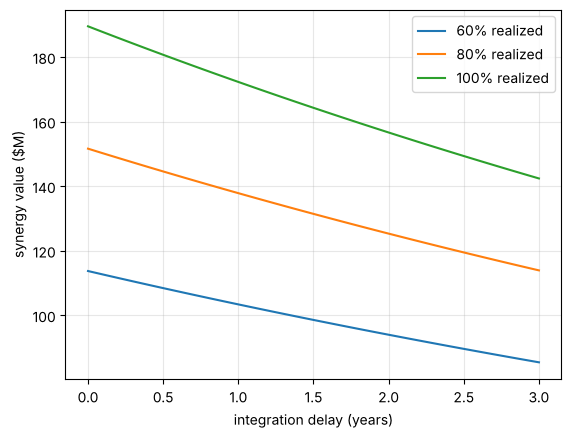

In [2]:
print(f"${ig.synergy_value(50, 5, 0.10, delay=3, realization=0.8):.1f}M")
d = np.linspace(0, 3, 61)
for rho in (0.6, 0.8, 1.0):
    plt.plot(d, [ig.synergy_value(50, 5, 0.10, delay=x, realization=rho) for x in d], label=f'{int(100*rho)}% realized')
plt.xlabel('integration delay (years)'); plt.ylabel('synergy value ($M)'); plt.legend(); plt.grid(True, alpha=0.3); plt.show()

## Part 2 · Correlated paths

Example 28-08.3: p = 0.6 and 0.5, socket $200M, second program costs $30M.

**Predict:** the gain if both fail with probability 0.35.

gain $10.0M


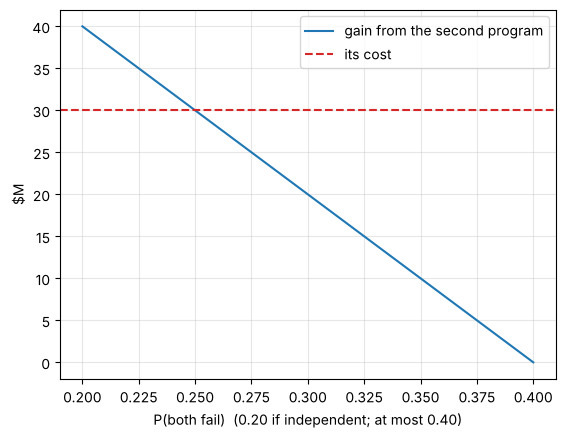

In [3]:
print(f"gain ${ig.parallel_gain(0.6, 0.5, 200, p_both_fail=0.35):.1f}M")
pb = np.linspace(0.2, 0.4, 41)
plt.plot(pb, [ig.parallel_gain(0.6, 0.5, 200, p_both_fail=x) for x in pb], label='gain from the second program')
plt.axhline(30, color='C3', ls='--', label='its cost')
plt.xlabel('P(both fail)  (0.20 if independent; at most 0.40)'); plt.ylabel('$M'); plt.legend(); plt.grid(True, alpha=0.3); plt.show()

## Part 3 · Export metrics

**Predict:** the TPP of an accelerator with 2,000 dense FP8 TFLOP/s.

In [4]:
chips = [('datacenter accelerator', 2000, 8, 800), ('mid-range accelerator', 400, 8, 600),
         ('inference card', 250, 8, 300), ('edge NPU', 150, 8, 60)]
for name, tops, bits, area in chips:
    t = ig.tpp(tops, bits); dens = ig.performance_density(t, area)
    if t >= 4800: a = '3A090.a.1'
    elif t >= 1600 and dens >= 5.92: a = '3A090.a.2'
    elif (2400 <= t < 4800 and 1.6 <= dens < 5.92) or (t >= 1600 and 3.2 <= dens < 5.92):
        a = '3A090.b band if designed or marketed for datacenters'
    else: a = 'below the 3A090 thresholds'
    print(f"{name:24s} TPP {t:7.0f}  density {dens:6.2f}  -> {a}")
print("Thresholds as coded from the 2023 text [R-659]; other controls (end use, entity list, other ECCNs) are not checked. Not legal advice.")

datacenter accelerator   TPP   16000  density  20.00  -> 3A090.a.1
mid-range accelerator    TPP    3200  density   5.33  -> 3A090.b band if designed or marketed for datacenters
inference card           TPP    2000  density   6.67  -> 3A090.a.2
edge NPU                 TPP    1200  density  20.00  -> below the 3A090 thresholds
Thresholds as coded from the 2023 text [R-659]; other controls (end use, entity list, other ECCNs) are not checked. Not legal advice.


## Part 4 · The register

Example 28-08.6's risks (probability, impact $M).

**Predict:** the expected loss if the license risk is resolved before signing.

before 49, license resolved 34, both mitigations 28


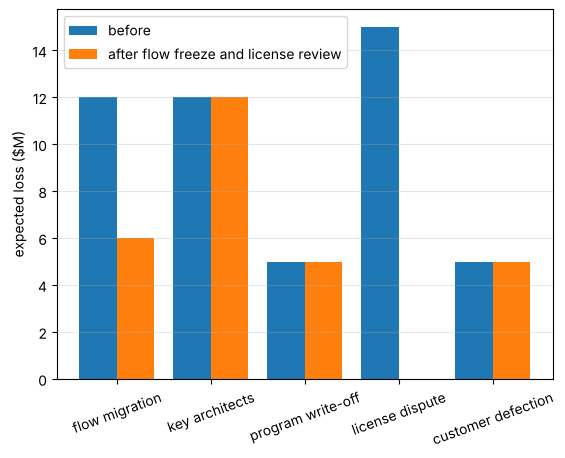

In [5]:
names = ['flow migration', 'key architects', 'program write-off', 'license dispute', 'customer defection']
before = [(0.30, 40), (0.20, 60), (0.50, 10), (0.10, 150), (0.25, 20)]
after = [(0.15, 40), (0.20, 60), (0.50, 10), (0.0, 150), (0.25, 20)]
print(f"before {ig.expected_loss(before):.0f}, license resolved {ig.expected_loss(before[:3] + [(0.0, 150)] + before[4:]):.0f}, both mitigations {ig.expected_loss(after):.0f}")
x = np.arange(len(names))
plt.bar(x - 0.2, [p*i for p, i in before], width=0.4, label='before')
plt.bar(x + 0.2, [p*i for p, i in after], width=0.4, label='after flow freeze and license review')
plt.xticks(x, names, rotation=20); plt.ylabel('expected loss ($M)'); plt.legend(); plt.grid(True, axis='y', alpha=0.3); plt.show()